# To Fix:
1. heisenberg plot fails when no_levels of WPT is 1 / 2/ 3
2. add kurtosis, crest factor, entropy, energy, etc calculations to utils as functions to be loaded as methods. They shouldn't be in test. Test folder usually contains codes for unit and integration tests not utilities.
3. calculate energy using WPT coefficients not reconstructed data at each node

https://sapienlabs.org/lab-talk/measuring-entropy-in-the-eeg/


In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats

# import matplotlib
# matplotlib.use('nbagg')
import matplotlib.pyplot as plt
import numpy as np

### Parameters

Specify parameters for synthetic data and wavelet transform

In [3]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [0.4, 1, 0.5]  # amplitude of each sine wave
frequencies = [5, 10, 20]  # frequency content of signal
phases = [0, np.deg2rad(45), 0]  # phase of each sine wave

duration = 300 / min(frequencies)  # duration of wave

trans_amp = [3 for _ in range(3)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db20"
levels = 4
mode = "symmetric"

sort_by = 'energy'  # 'energy', 'kurtosis', 'crest', 'False' -> freq
sort = "rec"  # 'rec' (reconstructed signal) 'coef' (transform coefficients)
# n_highest = 3

fft_lim = 50  # increase value to view more of the fft plots

### Generating synthetic data

Generate synthetic data with transients, noise, and harmonics. Plot the data with its FFT. 

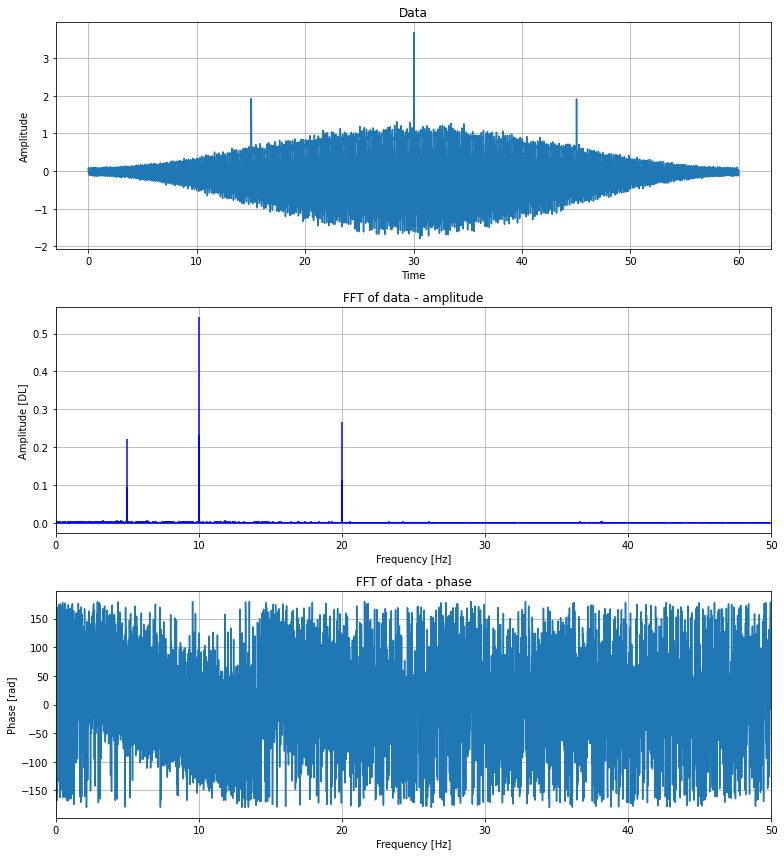

In [4]:
# generate sound wave
data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
transient_signal = sd.transients(trans_amp, trans_time, trans_dur, duration, sampling_rate)
data += transient_signal
data += sd.noise(std_noise,duration,sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

Calculating crest factor and energy

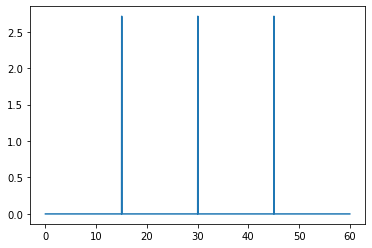

In [5]:
plt.plot(t_plot,transient_signal)
plt.show()

Wavelet transform

In [6]:
# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
rec = []

total_energy = stats.calc_energy(data)

# calculate energy, kurtosis, and crest factor of reconstructed signals
for node in tr_ob.get_level(level=levels, order="freq"):
    # node_data = node.data  # coefficients from transform

    # calculate inverse transform
    path = node.path
    rec_nodes = tr_ob.packet_nodes_for_rec(keep=[path])
    coeffs = tr_ob.nodes2data(rec_nodes)
    inverse = inv.inv_dwpt(coeffs, wavelet)[:signal_length]
    inverse_signal_length = len(inverse)

    # calculate fft of inverse
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )

    # calculate statistical measures
    entropy_node = stats.calc_entropy(node.energy, total_energy)
    kurtosis = stats.calc_kurtosis(inverse)
    skewness = stats.calc_skewness(inverse)
    crest = stats.calc_crest_factor(inverse)

    # add to list
    rec.append((node, inverse, fft, node.energy, kurtosis, crest, entropy_node, skewness))

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

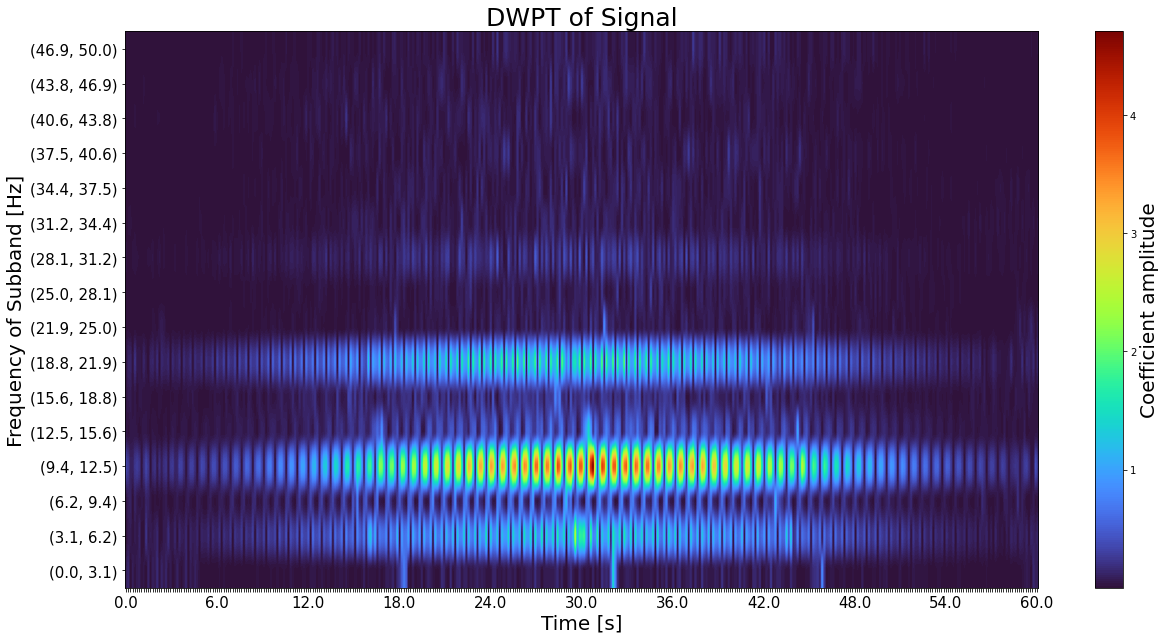

In [7]:
plot.heisenberg(tr_ob, max(t_plot))

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
data_train = []
for _, inverse, _, energy, kurtosis, crest, entropy_node, skewness in rec:
#     data_train.append(
#         (energy, kurtosis, crest, max(abs(inverse)), 
#         np.mean(inverse), stats.calc_skew(inverse))
#         )
    data_train.append(
        (energy, kurtosis, skewness)
        )

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 3
kmeans = KMeans(n_clusters=no_clusters)
kmeans.fit(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

3 clusters:

- high energy, low kurtosis, low skewness -> harmonic
- low energy, high kurtosis, high skewness -> transient
- low energy, medium kurtosis, low skewness -> noise

In [ ]:
data_train[:10]

In [ ]:
data_train[10:21]

In [ ]:
data_train[21:30]

### Reassigning Groups

Post-hoc reassignment of groups based on the energy and kurtosis of their clusters.

In [ ]:
def assign_labels(centers, labels, sort_by=1):
    """
    assign labels to clusters. Assign the highest cluster number to the centre with 
    highest energy. Then assign the rest in order of sort_by. The group numbers are reassigned
    to 1-indexed groups.

    Paramaters
    -----------
    centers: array
        array where each row is a centre of a cluster
    labels: list
        list of group assignments to reassign
    sort_by: int
        always sort out the highest energy because the harmonic can be separated
        from the rest by its much greater energy. Otherwise, sort by attribute
        number = sort_by of the centres. e.g. sort_by == 1 will sort the rest 
        by kurtosis, sort_by == 2 will sort by crest factor etc.
    """
    # sort labels by energy, highest cluster energy is highest group number
    sort_by_energy = np.argsort(centers[:, 0])

    # sort rest of the labels by kurtosis
    sort_rest = np.argsort(centers[:, sort_by])

    sort_rest = np.delete(
        sort_rest, # delete highest energy group form kurtosis
        np.where(sort_rest == sort_by_energy[-1])[0][0], 
        axis=0
        )
    sort_rest = np.append(sort_rest, None)

    # create mapping from old cluster labels to new cluster labels
    mapping = {}
    for new_label, index in enumerate(zip(sort_by_energy, sort_rest)):
        if new_label == len(sort_by_energy) - 1:  # highest group no has highest energy
            mapping[index[0]] = new_label + 1
        else:
            mapping[index[1]] = new_label + 1  # other group numbers are arranged by kurtosis

    # update labels
    reassigned_labels = [mapping[label] for label in labels]
    return reassigned_labels

In [ ]:
reassigned_labels = assign_labels(centers, labels)

### Plot result

Plot the assigned group against the frequency of the node. 

In [ ]:
# plot regular k-means
plt.bar([node.frequency_range[0] for node,*_ in rec], reassigned_labels)
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [ ]:
# apply PCA to training data
pca = PCA(n_components=len(data_train[0]))
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters)
kmeans_pca.fit(data_pca)

# convert centres back to regular feature space (energy, kurtosis, crest, etc.)
labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(pca.inverse_transform(kmeans_pca.cluster_centers_))
reassigned_pca_labels = assign_labels(centers_pca, labels_pca)

### Plot PCA result

The group number vs frequency for each node is plotted again after PCA is applied.

In [ ]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node,*_ in rec]
plt.bar([node.frequency_range[0] for node,*_ in rec], reassigned_pca_labels)
plt.tick_params
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print('energy, kurtosis, skewness')
print(np.round(eigenvectors,2))

print("Eigenvalues:", np.round(eigenvalues,2))

### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

In [ ]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={'projection': '3d'})

titles = ['Original Data', 'PCA Data']

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap('Set1')
    if i == 0:
        data_scatter = data_train
        centers_scatter = centers
        labels_scatter = reassigned_labels
    else:
        data_scatter = data_train
        centers_scatter = centers_pca
        labels_scatter = labels_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        c=[cmap(label) for label in labels_scatter])
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c='red', marker='x', s=100)
    
    ax.set_xlabel('Energy')
    ax.set_ylabel('Kurtosis')
    ax.set_zlabel('Skewness')
    ax.set_title(titles[i])

plt.show()

### Results

Plotting the reconstructed waves at each node alongside their assigned group number.

In [ ]:
def plot_reconstructions(rec, group=None):
    for i, rec in enumerate(rec):  # highest energy, kurtosis, etc.
        node, rec_wave, fft, *_ = rec
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = node.frequency_range
        ax[0].plot(t_plot, rec_wave)
        title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(fft),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed subband")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()

        # print info
        print(f"energy of recovered signal: {stats.calc_energy(rec_wave)}")
        print(f"kurtosis of recovered signal: {stats.calc_kurtosis(rec_wave)}")
        print(f"crest factor of recovered signal: {stats.calc_crest_factor(rec_wave)}")
        print()
        print(f"energy of node coefficients: {node.energy}")
        print(f"kurtosis of node coefficients: {node.kurtosis}")
        print(f"crest factor of node coefficients: {node.crest_factor}")

Change to group=reassign_pca_labels to display the groups assigned using PCA

In [ ]:
plot_reconstructions(rec, group=reassigned_labels)
# plot_reconstructions(rec, group=reassigned_pca_labels)